# 00 — Synthetic smoke test (offline)

**Goal:** validate the repository before downloading images or model weights. This notebook intentionally uses generated embeddings and labels, not a public benchmark. Its outputs prove only that the code path, artifacts, and figures work.

We will: (1) create synthetic query/candidate embeddings, (2) run initial-score, encoder-similarity, MMR, adaptive MMR, greedy DPP, and cluster-xQuAD rankings, (3) measure relevance/diversity/latency, and (4) persist CSV and PNG outputs. Plots use Seaborn's `darkgrid` style.

Run it from the repository root after `python -m pip install -e ".[dev]"`.

## 0. The Setup

In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
from IPython.display import display, Image

In [2]:
ROOT = Path.cwd()
if not (ROOT / "src" / "image_rerank").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from image_rerank.data import make_synthetic_queries
from image_rerank.rerankers import (
    original_rank, mmr_rerank, adaptive_mmr_rerank,
    greedy_dpp_rerank, cluster_aspect_probabilities, xquad_rerank,
)
from image_rerank.metrics import evaluate_ranking
from image_rerank.plots import plot_tradeoff, plot_metric_bars
from image_rerank.artifacts import ensure_dir, write_dataframe, write_json

In [3]:
ARTIFACTS = ROOT / "artifacts" / "demo"
ensure_dir(ARTIFACTS / "metrics")
ensure_dir(ARTIFACTS / "rankings")
ensure_dir(ARTIFACTS / "figures")
print(f"Repository root: {ROOT}")
print(f"Artifacts will be written to: {ARTIFACTS}")

Repository root: d:\01 Work\14-research-Image-MMR
Artifacts will be written to: d:\01 Work\14-research-Image-MMR\artifacts\demo


In [ ]:
# Check GPU Access
import torch
print({
    # "project_root": str(PROJECT_ROOT),
    # "python": platform.python_version(),
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
})

## 1. Generate a deterministic toy benchmark

Each query has one vector and a shortlist of image vectors. A small portion of image vectors is generated near the query vector; binary relevance is assigned using a similarity threshold. The initial ranking score is noisy to mimic a first-stage retriever.

This is intentionally artificial, and any measured scores below are not comparable to INQUIRE or DeepFashion.

In [4]:
synthetic_queries = make_synthetic_queries(
    n_queries=12,
    n_candidates=60,
    embedding_dim=64,
    seed=123,
)

example = synthetic_queries[0]
print("Number of queries:", len(synthetic_queries))
print("Candidates for first query:", len(example["image_ids"]))
print("Embedding dimension:", len(example["query_embedding"]))
print("Relevant candidates:", int(np.sum(example["relevance"])))

Number of queries: 12
Candidates for first query: 60
Embedding dimension: 64
Relevant candidates: 21


## 2. Run all rerankers

The encoder-similarity baseline sorts by the selected query–image cosine scores. MMR, adaptive MMR, DPP, and cluster-xQuAD use those same relevance scores so the comparison is focused on the ranking policy. `initial_clip` uses a separately supplied, noisy first-stage score.

In [5]:
metric_rows = []
ranking_rows = []

# Warm up model-free rerankers once so their first measured call excludes import/cold-start cost.
_warm = synthetic_queries[0]
_warm_x = np.asarray(_warm["image_embeddings"], dtype=np.float32)
_warm_scores = _warm_x @ np.asarray(_warm["query_embedding"], dtype=np.float32)
_ = original_rank(np.asarray(_warm["original_scores"]), top_k=50)
_ = original_rank(_warm_scores, top_k=50)
_ = mmr_rerank(_warm_scores, _warm_x, lambda_relevance=0.70, top_k=50)
_ = adaptive_mmr_rerank(_warm_scores, _warm_x, top_k=50)
_ = greedy_dpp_rerank(_warm_scores, _warm_x, top_k=50)
_ = xquad_rerank(_warm_scores, cluster_aspect_probabilities(_warm_x, n_clusters=6), lambda_relevance=0.70, top_k=50)

for query_data in synthetic_queries:
    query_id = query_data["query_id"]
    query_text = query_data["query"]
    query_embedding = np.asarray(query_data["query_embedding"], dtype=np.float32)
    image_embeddings = np.asarray(query_data["image_embeddings"], dtype=np.float32)
    initial_scores = np.asarray(query_data["original_scores"], dtype=np.float32)
    relevance = np.asarray(query_data["relevance"], dtype=np.int8)

    # Normalize the rows to protect cosine similarity against rounding drift.
    image_embeddings = image_embeddings / np.maximum(
        np.linalg.norm(image_embeddings, axis=1, keepdims=True), 1e-12
    )
    encoder_scores = image_embeddings @ query_embedding

    rankers = {
        "initial_clip": lambda: original_rank(initial_scores, top_k=50),
        "encoder_similarity": lambda: original_rank(encoder_scores, top_k=50),
        "mmr_fixed_0.70": lambda: mmr_rerank(
            encoder_scores, image_embeddings, lambda_relevance=0.70, top_k=50
        ),
        "adaptive_mmr": lambda: adaptive_mmr_rerank(
            encoder_scores, image_embeddings, top_k=50
        )[0],
        "greedy_dpp": lambda: greedy_dpp_rerank(encoder_scores, image_embeddings, top_k=50),
        "cluster_xquad": lambda: xquad_rerank(
            encoder_scores,
            cluster_aspect_probabilities(image_embeddings, n_clusters=6, random_state=42),
            lambda_relevance=0.70,
            top_k=50,
        ),
    }

    for method, rank_fn in rankers.items():
        start = time.perf_counter()
        order = rank_fn()
        latency_ms = (time.perf_counter() - start) * 1000.0
        values = evaluate_ranking(
            relevance, order, image_embeddings,
            k_relevance=50, k_diversity=10,
        )
        metric_rows.append({
            "query_id": query_id, "query": query_text, "method": method,
            "rerank_latency_ms": latency_ms, "data_type": "synthetic_smoke_test",
            **values,
        })
        for rank, candidate_idx in enumerate(order[:50], start=1):
            ranking_rows.append({
                "query_id": query_id, "method": method, "rank": rank,
                "image_id": str(query_data["image_ids"][candidate_idx]),
                "relevant": int(relevance[candidate_idx]),
            })

metrics_df = pd.DataFrame(metric_rows)
rankings_df = pd.DataFrame(ranking_rows)
print("Metrics rows:", metrics_df.shape)
print("Ranked candidate rows:", rankings_df.shape)
display(metrics_df.head())

Metrics rows: (72, 9)
Ranked candidate rows: (3600, 5)


,query_id,query,method,rerank_latency_ms,data_type,ap@50,ndcg@10,recall@10,ild@10
0,synthetic-000,synthetic query 0,initial_clip,0.0400,synthetic_smoke_test,0.857143,0.712552,0.285714,0.978226
1,synthetic-000,synthetic query 0,encoder_similarity,0.0416,synthetic_smoke_test,0.904762,0.550113,0.285714,0.947471
2,synthetic-000,synthetic query 0,mmr_fixed_0.70,0.5833,synthetic_smoke_test,0.904762,0.628511,0.333333,0.948817
3,synthetic-000,synthetic query 0,adaptive_mmr,0.6704,synthetic_smoke_test,0.809524,0.571635,0.285714,0.996570
4,synthetic-000,synthetic query 0,greedy_dpp,0.9557,synthetic_smoke_test,0.857143,0.625334,0.333333,0.948817


## 3. Aggregate and save metrics

The mean summarizes method behavior across queries. Standard deviation shows query-to-query variation. For a real claim, use paired bootstrap confidence intervals over queries; the next notebooks include that analysis.

In [6]:
summary = metrics_df.groupby("method", as_index=False).agg(
    **{
        "ap@50_mean": ("ap@50", "mean"),
        "ap@50_std": ("ap@50", "std"),
        "ndcg@10_mean": ("ndcg@10", "mean"),
        "ndcg@10_std": ("ndcg@10", "std"),
        "recall@10_mean": ("recall@10", "mean"),
        "recall@10_std": ("recall@10", "std"),
        "ild@10_mean": ("ild@10", "mean"),
        "ild@10_std": ("ild@10", "std"),
        "rerank_latency_ms_mean": ("rerank_latency_ms", "mean"),
        "rerank_latency_ms_p95": ("rerank_latency_ms", lambda x: float(np.percentile(x, 95))),
    }
)

write_dataframe(ARTIFACTS / "metrics" / "synthetic_per_query_metrics.csv", metrics_df)
write_dataframe(ARTIFACTS / "metrics" / "synthetic_summary.csv", summary)
write_dataframe(ARTIFACTS / "rankings" / "synthetic_rankings.csv", rankings_df)
write_json(ARTIFACTS / "metrics" / "synthetic_run_metadata.json", {
    "n_queries": len(synthetic_queries),
    "n_candidates": len(example["image_ids"]),
    "seed": 123,
    "warning": "Synthetic smoke-test results only; not benchmark performance.",
})
display(summary.round(4))

,method,ap@50_mean,ap@50_std,ndcg@10_mean,ndcg@10_std,recall@10_mean,recall@10_std,ild@10_mean,ild@10_std,rerank_latency_ms_mean,rerank_latency_ms_p95
0,adaptive_mmr,0.9127,0.0603,0.5688,0.1660,0.2619,0.0849,0.9895,0.0180,0.6735,0.8909
1,cluster_xquad,0.9286,0.0626,0.6576,0.1772,0.3135,0.0745,0.9532,0.0166,16.8767,18.3077
2,encoder_similarity,0.9286,0.0626,0.6457,0.1731,0.3016,0.0769,0.9515,0.0147,0.0231,0.0347
3,greedy_dpp,0.9206,0.0469,0.6489,0.1789,0.3016,0.0821,0.9556,0.0172,0.9403,1.1834
4,initial_clip,0.8849,0.0555,0.5691,0.1800,0.2659,0.0657,0.9777,0.0227,0.0292,0.0421
5,mmr_fixed_0.70,0.9246,0.0591,0.6326,0.1638,0.2976,0.0736,0.9579,0.0175,0.5235,0.6711


## 4. Plot metrics with Seaborn darkgrid

The first plot makes the trade-off visible: x-axis is embedding-space diversity, y-axis is candidate-list AP@50, and marker size represents measured reranking latency. Larger ILD is not automatically better; inspect it with relevance rather than alone.

d:\01 Work\14-research-Image-MMR\artifacts\demo\figures\synthetic_tradeoff.png
d:\01 Work\14-research-Image-MMR\artifacts\demo\figures\synthetic_metric_comparison.png


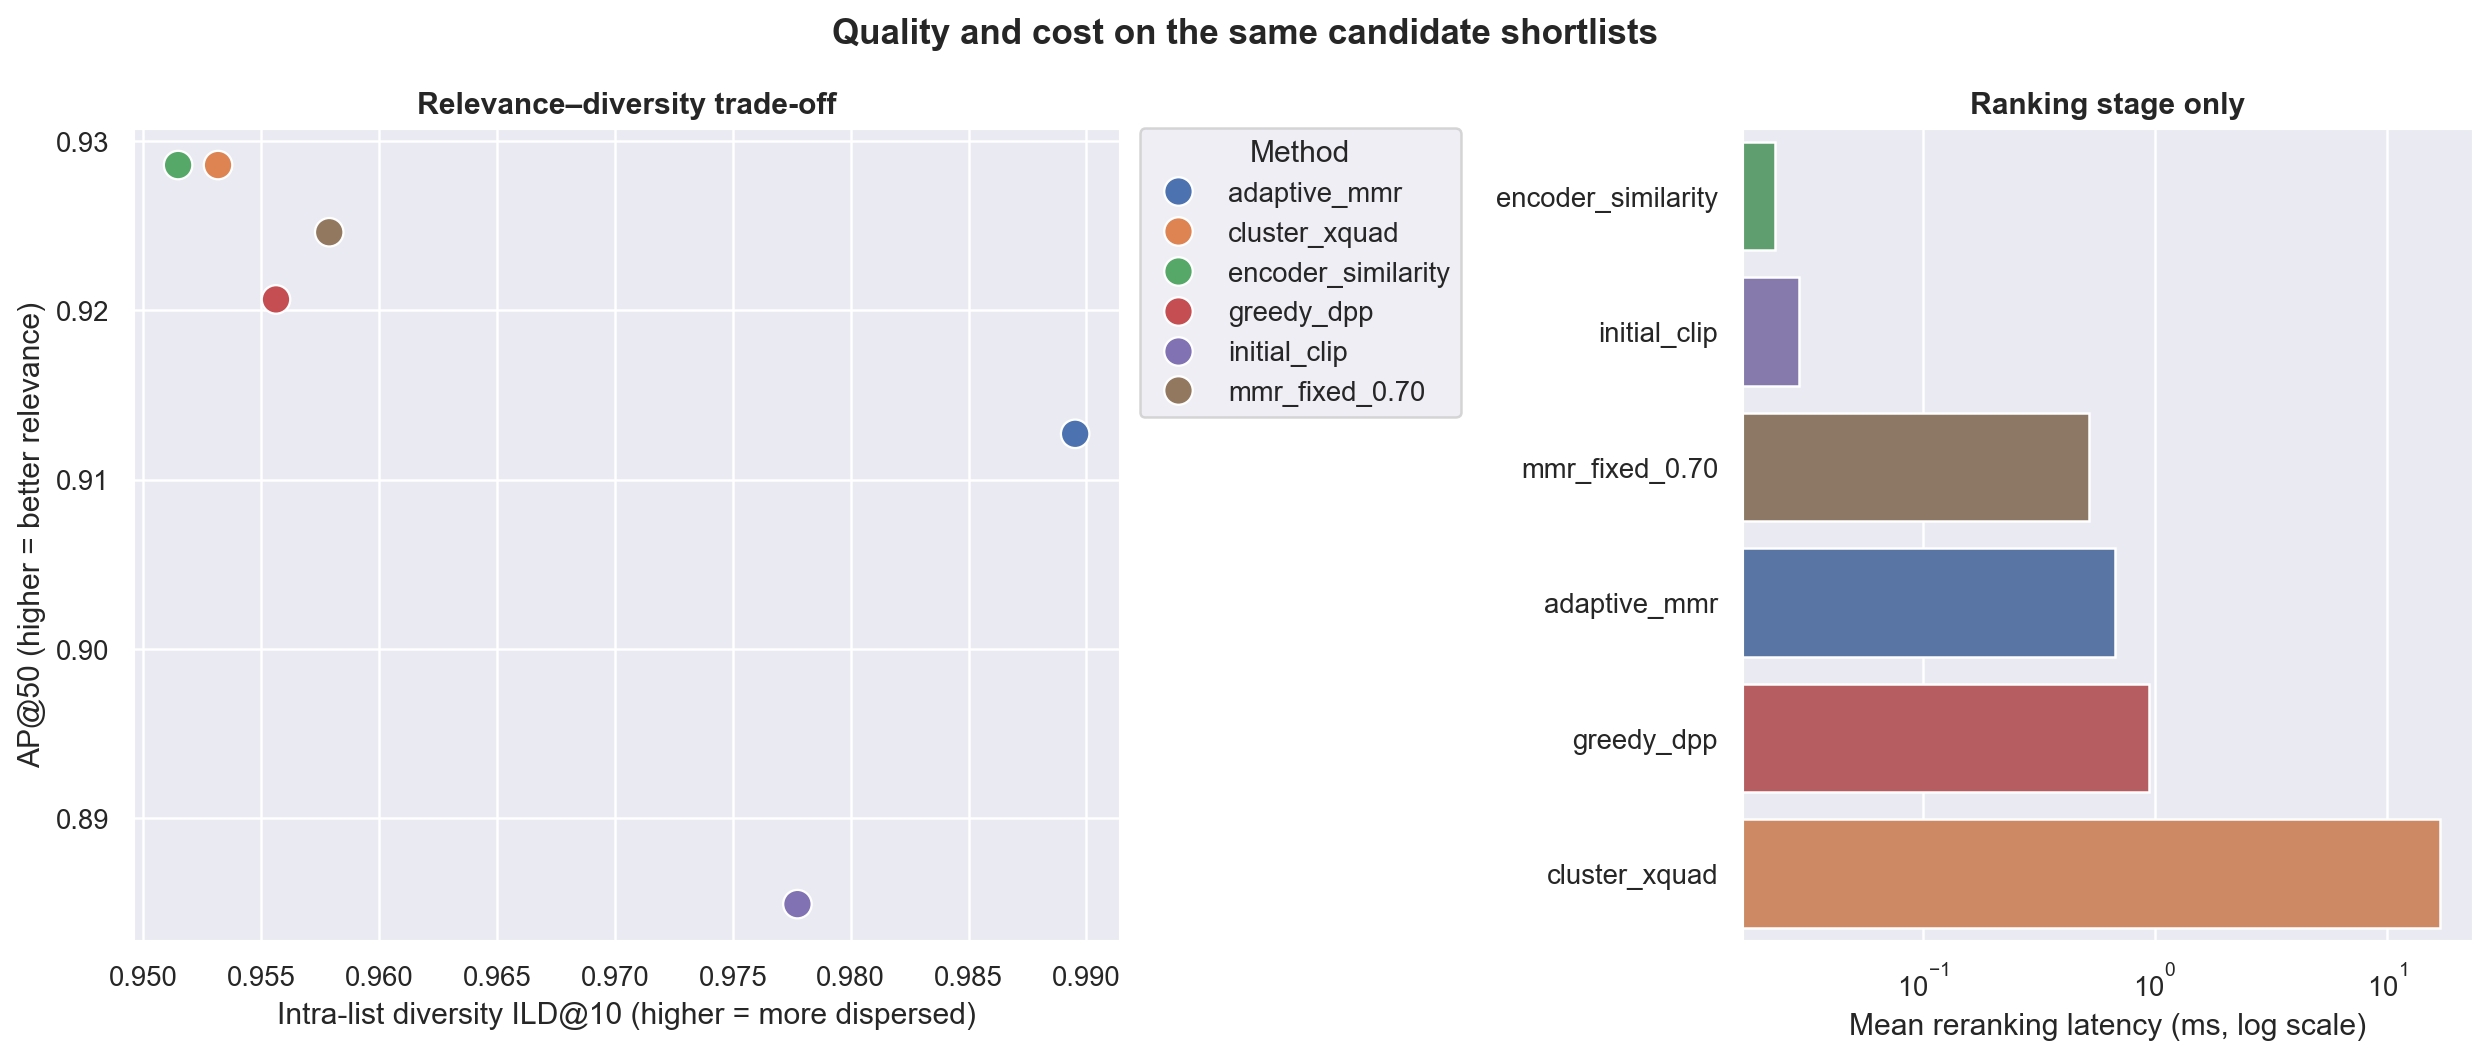

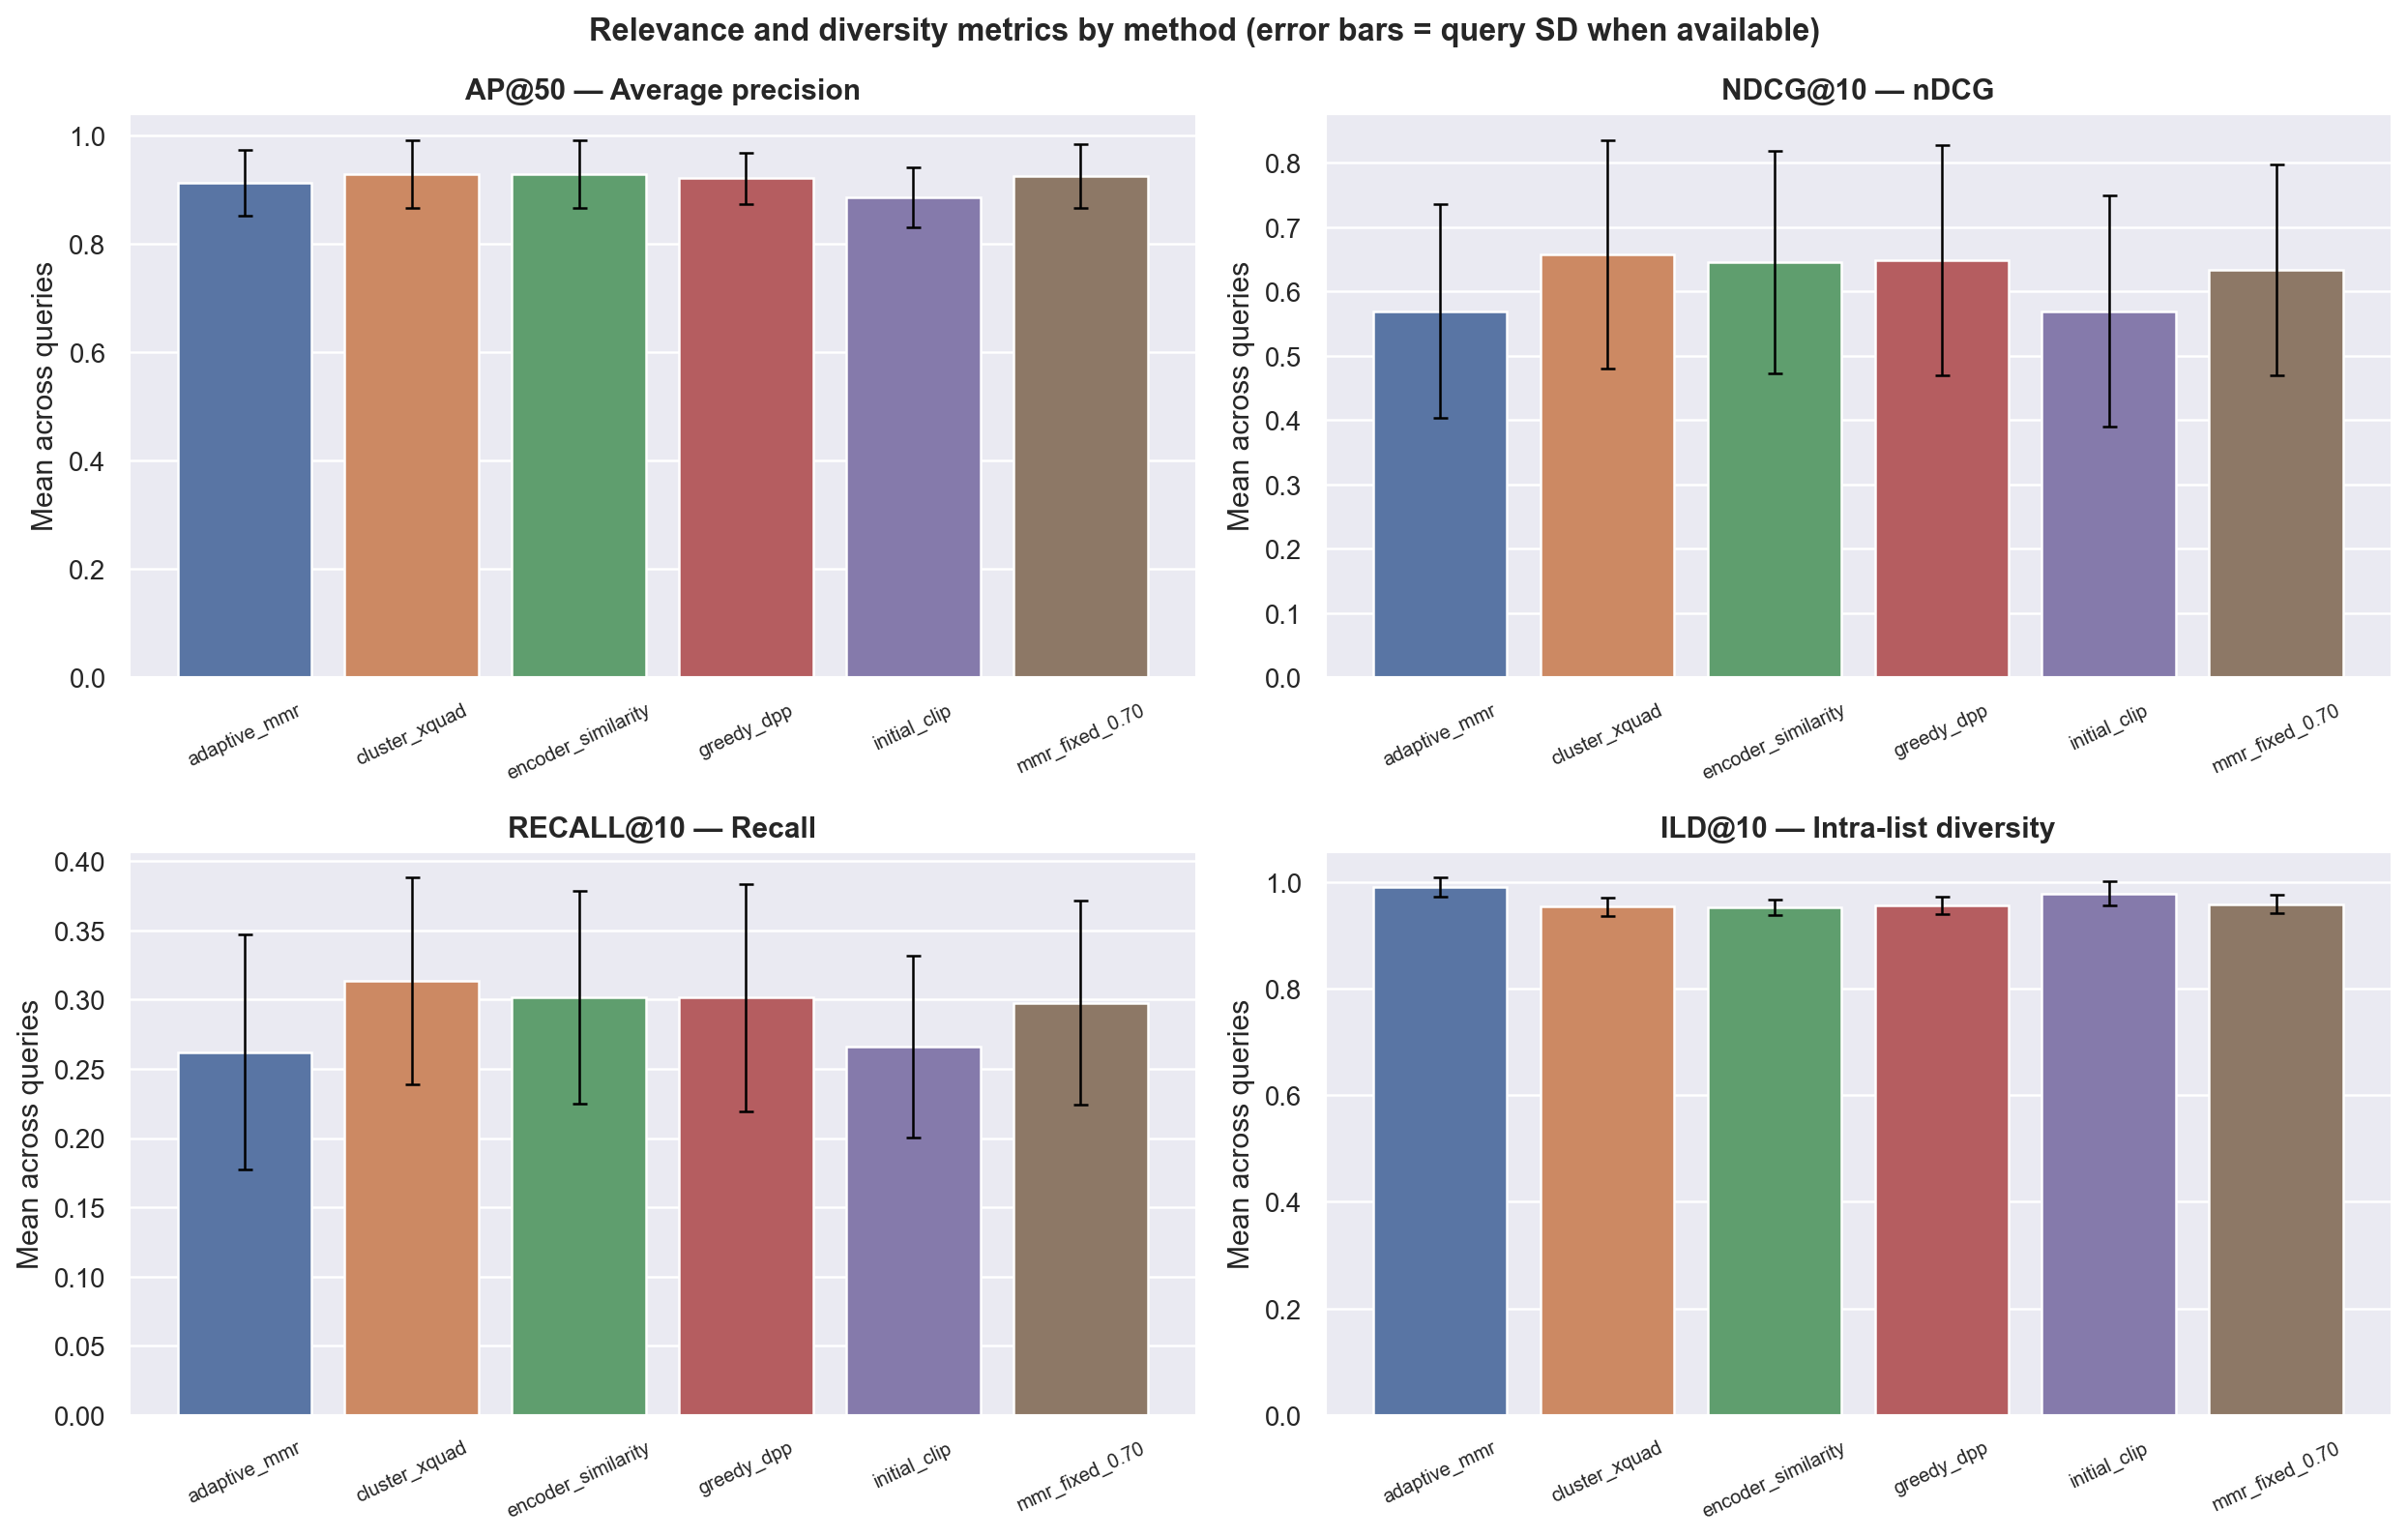

In [7]:
tradeoff_path = plot_tradeoff(
    metrics_df, ARTIFACTS / "figures" / "synthetic_tradeoff.png"
)
bar_path = plot_metric_bars(
    summary, ARTIFACTS / "figures" / "synthetic_metric_comparison.png"
)
print(tradeoff_path)
print(bar_path)
display(Image(filename=str(tradeoff_path)))
display(Image(filename=str(bar_path)))

## 5. Smoke-test checklist

- [ ] All six methods produced a unique candidate ordering.
- [ ] Metrics contain finite values.
- [ ] The CSV files and PNG figures exist under `artifacts/demo/`.
- [ ] The test suite passes with `pytest`.

Only after these pass should you proceed to the public dataset.

In [16]:
expected = [
    ARTIFACTS / "metrics" / "synthetic_per_query_metrics.csv",
    ARTIFACTS / "metrics" / "synthetic_summary.csv",
    ARTIFACTS / "rankings" / "synthetic_rankings.csv",
    tradeoff_path,
    bar_path,
]
for path in expected:
    assert path.exists(), f"Missing artifact: {path}"
assert metrics_df["method"].nunique() == 6
assert np.isfinite(metrics_df.select_dtypes(include=[np.number]).to_numpy()).all()
print("Smoke test passed. Synthetic metrics must not be reported as research results.")

Smoke test passed. Synthetic metrics must not be reported as research results.


## The End